### Installation

In [ ]:
!pip install unsloth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.3/29.3 MB 187.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 155.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 57.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 136.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 128.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 133.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 142.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 111.8 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [un

### Unsloth

Here we load the model and tokenizer using FastModel from Unsloth. We fine tune on gemma 3 with 4B parameters on 4bit and not full fine tuning. The maximum sequence length is 1024.

In [ ]:
from unsloth import FastModel
import torch

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 1024,
    load_in_4bit = True,
    full_finetuning = False,
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1108 20:35:58.739000 4440 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1108 20:35:58.780000 4440 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.034 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

We now add LoRA adapters so we only need to update a small amount of parameters!
vision layer is False because we only want to fine tune the text capability of the model. set r to small number when the dataset is also small and lora_alpha=r.

In [ ]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers = False,
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True, #my little pony

    r = 8,
    lora_alpha = 8,
    lora_dropout = 0,
    bias = "none",
    random_state = 2027,
)

# Data Prep

In [ ]:
from unsloth.chat_templates import CHAT_TEMPLATES

for name in CHAT_TEMPLATES.keys():
    print(name)

unsloth
zephyr
chatml
mistral
llama
vicuna
vicuna_old
vicuna old
alpaca
gemma
gemma_chatml
gemma2
gemma2_chatml
llama-3
llama3
phi-3
phi-35
phi-3.5
llama-3.1
llama-31
llama-3.2
llama-3.3
llama-32
llama-33
qwen-2.5
qwen-25
qwen25
qwen2.5
qwen-2.5-coder
qwen-25-coder
qwen2.5-coder
qwen25-coder
phi-4
gemma-3
gemma3
qwen-3
qwen3
gemma-3n
gemma3n
gemma-4
gemma4
gemma-4-thinking
gemma4-thinking
gpt-oss
gptoss
qwen3-instruct
qwen3-thinking
lfm-2
lfm-2.5
starling
yi-chat


We initialize the chat template of gemma 3 because we fine tune on gemma 3 model.

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

We use the dataset of ACELEDA Frequently Asked Questions.

In [ ]:
from datasets import load_dataset
dataset = load_dataset("csv", data_files="/content/drive/MyDrive/Colab Notebooks/Meikuan Project/dataasilida_cleaned.csv")

Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['input,output', '__index_level_0__'],
        num_rows: 521
    })
})

In [ ]:
import pandas as pd
df = dataset["train"].to_pandas()
pd.set_option("display.max_colwidth", None)
df.head()

,"input,output",__index_level_0__
0,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី
1,លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ដូចខាងក្រោម៖ -អាចដកសាច់ប្រាក់បានឆាប់រហ័សពីគ្រប់ម៉ាស៊ីន អេធីអឹម ទាំងអស់ដែលមានស្លាកសញ្ញា ចេស៊ីប៊ី ធម្មតា នៅក្នុង និងក្រៅប្រទេស ២៤ម៉ោង ក្នុងមួយថ្ងៃ និង ៧ថ្ងៃ ក្នុងមួយសប្តាហ៍។ -អាចទូទាត់ចំណាយផ្សេងៗ នៅតាមហាងទំនិញ សណ្ឋាគារ ឬក្រុមហ៊ុន នានាដែលមានម៉ាស៊ីនឆូតកាត ឬ ឧបករណ៍អេឡិចត្រូនិក ផ្សេងទៀត ដែលមានស្លាកសញ្ញា ចេស៊ីប៊ី ធម្មតា នៅក្នុង និងក្រៅប្រទេស។ -អាចបញ្ជាទិញ ទំនិញ ឬកក់សំបុត្រយន្តហោះ ឬកក់បន្ទប់សណ្ឋាគារ តាម Internet/E-Commerce ។ល។ -ផ្ទេរប្រាក់តាមរយៈម៉ាស៊ីន អេធីអឹម របស់ធនាគារ អេស៊ីលីដា។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូវអត្ថប្រយោជន៍អ្វីខ្លះ
2,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បានដោយគ្រាន់តែ បើកគណនីមួយនៅធនាគារ អេស៊ីលីដា សាខាណាមួយដែលនៅជិតលោកអ្នកបំផុត ហើយគណនីនោះអាចជា គណនីបញ្ញើសំចៃ គណនីតាមតម្រូវការ ឬគណនីចរន្ត បន្ទាប់មកលោកអ្នកគ្រាន់តែបំពេញពាក្យដើម្បីស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា តែប៉ុណ្ណោះ។,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន
3,លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរិក តាមម៉ាស៊ីនអេធីអឹម អេស៊ីលីដា និងម៉ាស៊ីនអេធីអឹម ធនាគារផ្សេងក្នុង និងក្រៅប្រទេស និងទូទាត់ថ្លៃទំនិញ ឬសេវាកម្ម តាមម៉ាស៊ីនឆូតកាត និងអ៊ីនធើណែត (Online Shopping) បានរហូតដល់ ៦០០០ដុល្លារអាមេរិក ដែលអាចធ្វើប្រតិបត្តិការបាន ២៥ប្រតិបត្តិការ ក្នុងមួយថ្ងៃ។,តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដកប្រាក់តាម ម៉ាស៊ីនអេធីអឹម និងទូទាត់ថ្លៃទំនិញ ឬសេវាកម្ម តាមម៉ាស៊ីន ឆូតកាត បានចំនួនប៉ុន្មាន និងប៉ុន្មានប្រតិបត្តិការក្នុងមួយថ្ងៃ
4,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេល ៥ឆ្នាំ ទើបផុតកំណត់។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មានឆ្នាំ


change the columns name to something easy to recognize and not special character.

In [ ]:
dataset = dataset.rename_column("input,output", "answer")

In [ ]:
dataset = dataset.rename_column("__index_level_0__", "question")

In [ ]:
df = dataset["train"].to_pandas()
pd.set_option("display.max_colwidth", None)
df.head()

,answer,question
0,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី
1,លោកអ្នកទទួលបានអត្ថប្រយោជន៍ពីការប្រើប្រាស់ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ដូចខាងក្រោម៖ -អាចដកសាច់ប្រាក់បានឆាប់រហ័សពីគ្រប់ម៉ាស៊ីន អេធីអឹម ទាំងអស់ដែលមានស្លាកសញ្ញា ចេស៊ីប៊ី ធម្មតា នៅក្នុង និងក្រៅប្រទេស ២៤ម៉ោង ក្នុងមួយថ្ងៃ និង ៧ថ្ងៃ ក្នុងមួយសប្តាហ៍។ -អាចទូទាត់ចំណាយផ្សេងៗ នៅតាមហាងទំនិញ សណ្ឋាគារ ឬក្រុមហ៊ុន នានាដែលមានម៉ាស៊ីនឆូតកាត ឬ ឧបករណ៍អេឡិចត្រូនិក ផ្សេងទៀត ដែលមានស្លាកសញ្ញា ចេស៊ីប៊ី ធម្មតា នៅក្នុង និងក្រៅប្រទេស។ -អាចបញ្ជាទិញ ទំនិញ ឬកក់សំបុត្រយន្តហោះ ឬកក់បន្ទប់សណ្ឋាគារ តាម Internet/E-Commerce ។ល។ -ផ្ទេរប្រាក់តាមរយៈម៉ាស៊ីន អេធីអឹម របស់ធនាគារ អេស៊ីលីដា។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ផ្តល់នូវអត្ថប្រយោជន៍អ្វីខ្លះ
2,លោកអ្នកអាចស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បានដោយគ្រាន់តែ បើកគណនីមួយនៅធនាគារ អេស៊ីលីដា សាខាណាមួយដែលនៅជិតលោកអ្នកបំផុត ហើយគណនីនោះអាចជា គណនីបញ្ញើសំចៃ គណនីតាមតម្រូវការ ឬគណនីចរន្ត បន្ទាប់មកលោកអ្នកគ្រាន់តែបំពេញពាក្យដើម្បីស្នើសុំ ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា តែប៉ុណ្ណោះ។,តើធ្វើដូចម្តេចទើបខ្ញុំអាច ស្នើសុំប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា បាន
3,លោកអ្នកអាចដកប្រាក់បានរហូតដល់ ១០០០០ដុល្លារអាមេរិក តាមម៉ាស៊ីនអេធីអឹម អេស៊ីលីដា និងម៉ាស៊ីនអេធីអឹម ធនាគារផ្សេងក្នុង និងក្រៅប្រទេស និងទូទាត់ថ្លៃទំនិញ ឬសេវាកម្ម តាមម៉ាស៊ីនឆូតកាត និងអ៊ីនធើណែត (Online Shopping) បានរហូតដល់ ៦០០០ដុល្លារអាមេរិក ដែលអាចធ្វើប្រតិបត្តិការបាន ២៥ប្រតិបត្តិការ ក្នុងមួយថ្ងៃ។,តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដកប្រាក់តាម ម៉ាស៊ីនអេធីអឹម និងទូទាត់ថ្លៃទំនិញ ឬសេវាកម្ម តាមម៉ាស៊ីន ឆូតកាត បានចំនួនប៉ុន្មាន និងប៉ុន្មានប្រតិបត្តិការក្នុងមួយថ្ងៃ
4,ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេល ៥ឆ្នាំ ទើបផុតកំណត់។,តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មានឆ្នាំ


In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['answer', 'question'],
        num_rows: 521
    })
})

Check for the number of empty value in each column and drop it out.

In [ ]:
for split in dataset.keys():
    df_split = dataset[split].to_pandas()
    print(df_split.isnull().sum())


answer      7
question    0
dtype: int64


In [ ]:
dataset = dataset.filter(lambda example: example['question'] is not None and example['answer'] is not None)
dataset

Filter:   0%|          | 0/521 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['answer', 'question'],
        num_rows: 514
    })
})

In [ ]:
dataset['train']['question'][0]
dataset['train']['answer'][0]

'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។'

Format the structure of the training dataset to follow its chat template.

In [ ]:
def formatting_prompts_func(examples):
    instructions = examples["question"]
    outputs      = examples["answer"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': str(instruction).strip(" ").replace("\\n", "\n")
          },
          {
            "role": "assistant", 'content': str(output).replace("\\n", "\n")
          }
      ]
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False).removeprefix("<bos>")
      texts.append(text)
    return {"text":texts}



map the question and answer into a column call text.

In [ ]:
dataset = dataset.map(formatting_prompts_func, batched = True,)

Map:   0%|          | 0/514 [00:00<?, ? examples/s]

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['answer', 'question', 'text'],
        num_rows: 514
    })
})

In [ ]:
dataset['train']['text'][0]

'<start_of_turn>user\nតើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>\n<start_of_turn>model\nប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>\n'

<a name="Train"></a>
### Train the model
We split 1% of the dataset for validation. since the data is small we only need per_device_train_batch_size = 8. we train for 2 epochs and use bf16 since we're training on L4 GPU.

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# Hold out 10% of the data for validation
split = dataset["train"].train_test_split(test_size = 0.1, seed = 2027)
print(split)

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = split["train"],
    eval_dataset = split["test"],
    dataset_text_field = "text",
    #max_seq_length = 2048,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 8,
        gradient_accumulation_steps = 1,
        warmup_steps = 5,
        num_train_epochs = 2,
        #max_steps = 60,
        learning_rate = 2e-4,
        #fp16 = not is_bfloat16_supported(),
        #bf16 = is_bfloat16_supported(),
        bf16=True,
        logging_steps = 1,
        #optim = "adamw_8bit",
        optim = "adamw_torch",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 2027,
        output_dir = "outputs",
        # --- validation ---
        per_device_eval_batch_size = 8,
        eval_strategy = "steps",
        eval_steps = 10,
        save_strategy = "steps",
        save_steps = 10,
        save_total_limit = 2,
        load_best_model_at_end = True,      # keep the checkpoint with the lowest validation loss
        metric_for_best_model = "eval_loss",
        greater_is_better = False,
        report_to = "none", # Use this for WandB etc
    ),
)

DatasetDict({
    train: Dataset({
        features: ['answer', 'question', 'text'],
        num_rows: 462
    })
    test: Dataset({
        features: ['answer', 'question', 'text'],
        num_rows: 52
    })
})


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/462 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/52 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


This part we initialize the training algorithm to train on the response only.

In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Map:   0%|          | 0/462 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Let's verify masking the instruction part is done! Let's print the 100th row again:

In [ ]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nអ្វីជាសេវាទូទាត់រហ័ស<end_of_turn>\n<start_of_turn>model\nសេវាទូទាត់រហ័សជាសេវាផ្ទេរប្រាក់ និងទូទាត់សងប្រាក់ជាប្រាក់រៀលឆ្លងគ្រឹះស្ថានដែលអាច អោយអតិថិជនទទួលបានមូលនិធិភ្លាមៗ ។<end_of_turn>\n'

Now let's print the masked out example, I should see only the answer is present:

In [ ]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

'                      សេវាទូទាត់រហ័សជាសេវាផ្ទេរប្រាក់ និងទូទាត់សងប្រាក់ជាប្រាក់រៀលឆ្លងគ្រឹះស្ថានដែលអាច អោយអតិថិជនទទួលបានមូលនិធិភ្លាមៗ ។<end_of_turn> '

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA L4. Max memory = 22.034 GB.
4.32 GB of memory reserved.


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [ ]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 462 | Num Epochs = 2 | Total steps = 116
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 1 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_10", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, GQA_SHARED_HEADS=2, HAS_FULL_BLOCKS=True, IS_DIVISIBLE=False, OUTPUT_LOGSUMEXP=True, OUTPUT_MAX=False, PRESCALE_QK=False, QK_HEAD_DIM=256, QK_HEAD_DIM_ROUNDED=256, ROWS_GUARANTEED_SAFE=False, SAFE_HEAD_DIM=True, SM_SCALE=0.0625, SPARSE_KV_BLOCK_SIZE=128, SPARSE_Q_BLOCK_SIZE=128, USE_TMA=False, V_HEAD_DIM=256, V_HEAD_DIM_ROUNDED=256, WRITE_DQ=True, num_stages=1, num_warps=4", "best_time": 4.1451520919799805, "best_triton_pos": 0}
Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_19", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, G

Step,Training Loss,Validation Loss
10,1.983375,1.943996
20,1.667144,1.632630
30,1.544700,1.513787
40,1.603626,1.433789
50,1.483552,1.374734
60,0.994582,1.341295
70,1.207427,1.309548
80,1.218462,1.284100
90,1.117959,1.261921
100,1.172129,1.246629


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_61", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, GQA_SHARED_HEADS=2, HAS_FULL_BLOCKS=True, IS_DIVISIBLE=False, OUTPUT_LOGSUMEXP=True, OUTPUT_MAX=False, PRESCALE_QK=False, QK_HEAD_DIM=256, QK_HEAD_DIM_ROUNDED=256, ROWS_GUARANTEED_SAFE=False, SAFE_HEAD_DIM=True, SM_SCALE=0.0625, SPARSE_KV_BLOCK_SIZE=128, SPARSE_Q_BLOCK_SIZE=128, USE_TMA=False, V_HEAD_DIM=256, V_HEAD_DIM_ROUNDED=256, WRITE_DQ=True, num_stages=1, num_warps=4", "best_time": 3.84716796875, "best_triton_pos": 0}
Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_71", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, GQA_SH

Filter:   0%|          | 0/52 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-10/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-10.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-30/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-30.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-40/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-40.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-50/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-50.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-60/tokenizer_config.json.
Unsloth: 

The total step of training = 462×2 / 8×1 = 116. This training is smartly move the computing unit in between CPU and GPU.

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

512.759 seconds used for training.
8.55 minutes used for training.
Peak reserved memory = 5.168 GB.
Peak reserved memory for training = 0.848 GB.
Peak reserved memory % of max memory = 23.455 %.
Peak reserved memory for training % of max memory = 3.849 %.


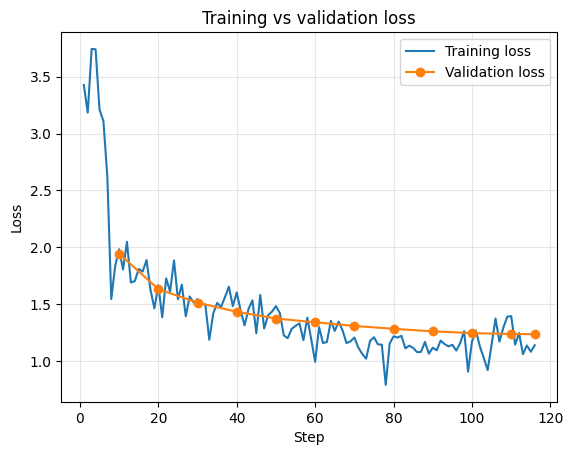

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

hist  = trainer.state.log_history
train = pd.DataFrame([h for h in hist if "loss" in h])
val   = pd.DataFrame([h for h in hist if "eval_loss" in h])

plt.plot(train["step"], train["loss"], label="Training loss")
plt.plot(val["step"], val["eval_loss"], "o-", label="Validation loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

We can see that the training loss start from 3.4 to 1.2 and the validation loss start from 1.9 to 1.25. The training and validation loss can possibly be further reduce with more training step.

# Inference

Base Model

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type": "text", "text": "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មានឆ្នាំ"}],
}]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(
    text=text,
    add_special_tokens=False,   # prompt already has <bos>
    return_tensors="pt",
).to("cuda")

# Turn LoRA adapters off → original base model
with model.disable_adapter():
    outputs = model.generate(
      **inputs,
      max_new_tokens = 1024,
      temperature = 0.5,
      top_p = 0.95,
      top_k = 64,
      repetition_penalty = 1.15,   # discourages repeating the same text
)

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
print(tokenizer.decode(new_tokens, skip_special_tokens=True))

ប័ណ្ណឥណពន្ធចេស្កាប៊ី (Chezyb) នៃក្រុមផលិតផល Aeilida ធម្មតា មិនត្រូវបានកំណត់ឱ្យមានសុពលភាពដែលជាក់ស្តែងទេ។ ប៉ុន្តែ, តាមរយៈការសិក្សាស្រាវជ្រាវ យើងអាចយល់ឃើញថា ឱសថទាំងនេះ ត្រូវតែប្រើប្រាស់ entro un periodo di validità di 3 anni dal giorno della produzione.

ដូច្នេះ, បើយើងគិតពីថ្ងៃផលិត, ឱសថ Chezyb នៃក្រុម Aeilida ធម្មតា ទំនងជាអាចប្រើប្រាស់បានរហូតដល់រយៈពេល 3 ปีក្រោយថ្ងៃផលិត។ ប៉ុន្តែសូមបញ្ជាក់ថា ការប្រើប្រាស់ គួរតែធ្វើឡើងក្រោមការណែនាំរបស់វេជ្ជបណ្ឌិត ដើម្បីធានាសុវត្ថិភាព និងប្រសិទ្ធភាព។


Fine-Tuned Model

In [ ]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(
    tokenizer,
    chat_template="gemma-3",
)

messages = [{
    "role": "user",
    "content": [{
        "type": "text",
        "text": "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មានឆ្នាំ",
    }]
}]

# Convert messages into a text prompt
text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,  # Important!
    add_generation_prompt=True,
)

# Tokenize the prompt
inputs = tokenizer(text, return_tensors="pt").to("cuda")

# Generate response
outputs = model.generate(
    **inputs,
    max_new_tokens = 1024,
    temperature = 0.5,
    top_p = 0.95,
    top_k = 64,
    repetition_penalty = 1.15,   # discourages repeating the same text
)

# Decode generated tokens
response = tokenizer.batch_decode(
    outputs,
    skip_special_tokens=True
)

print(response[0])

user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មានឆ្នាំ
model
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេល ៥ឆ្នាំ។


save trained modell locally

In [ ]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")

Unsloth: Restored added_tokens_decoder metadata in gemma-3/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma-3.


['gemma-3/processor_config.json']

load saved model

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "gemma-3",
        max_seq_length = 1024,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{
        "type": "text",
        "text": "តើ​សេវាអេស៊ីលីដាម៉ូបាល តម្រូវ​ឲ្យ​មាន​ប្រាក់តម្តល់​ដំបូង និង​សមតុល្យ អប្បបរមា ឬទេ",
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,  # Important!
    add_generation_prompt=True,
)
inputs = tokenizer(text, return_tensors="pt").to("cuda")

from transformers import TextStreamer
_ = model.generate(
    **inputs,
    max_new_tokens = 1024, # Increase for longer outputs!
    temperature = 0.5, top_p = 0.95, top_k = 64,
    repetition_penalty = 1.15,
    streamer = TextStreamer(tokenizer, skip_prompt = True, skip_special_tokens = True),
)

ការប្រើប្រាស់​សេវាអេស៊ីលីដាម៉ូបាល មិនទាមទារ​ឲ្យ​មាន​ប្រាក់តម្តល់​ដំបូង​ឡើយ ប៉ុន្តែ​ត្រូវ​បាន​កំណត់​ថា សុទ្ធតែ​អាច​ធ្វើ​ប្រតិបត្តិការ​ជាមួយ​គណនី​ដែលមាន​សមតុល្យ​គ្រប់គ្រាន់។


# Fine-Tune other model for Khmer Language

In [ ]:
!pip install unsloth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.3/29.3 MB 27.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 85.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 74.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 92.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 120.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 71.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 136.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 160.7 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [unslot

We use gemma 4 with 12B parameters.

In [ ]:
from unsloth import FastModel
import torch

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-4-12b-it",
    max_seq_length = 2048,
    load_in_4bit = True,
    full_finetuning = False,
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1108 21:30:54.469000 2290 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1108 21:30:54.487000 2290 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.3: Fast Gemma4_Unified patching. Transformers: 5.17.0.
   \\   /|    NVIDIA RTX PRO 6000 Blackwell Server Edition. Num GPUs = 1. Max memory: 94.971 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 12.0. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/677 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Gemma4UnifiedTextDecoderLayer).


This time we set r=lora_alpha=64 because the dataset is alot.

In [ ]:
model = FastModel.get_peft_model(
    model,
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True,

    r = 64,
    lora_alpha = 64,
    lora_dropout = 0,
    bias = "none",
    random_state = 2026,
)

Use gemma 4 chat template.

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-4",
)

We use dr. rina buoy's dataset contain factual general question/answer pair. the tone of the dataset is like a teacher explain student's question in an easy to understand way and short straight to the point.

In [ ]:
from datasets import load_dataset

ds = load_dataset("rinabuoy/text-pairs-khmer-part-2")

README.md:   0%|          | 0.00/317 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 93.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/179084 [00:00<?, ? examples/s]

rename it's column called "text" to "question" because in the next step we will map the Q&A format into a single column called "text".

In [ ]:
ds = ds.rename_column("text", "question")

In [ ]:
import pandas as pd
df = ds["train"].to_pandas()
pd.set_option("display.max_colwidth", None)
df.head()

,question,summary
0,ហេតុអ្វីបានជាទឹកសមុទ្រ១៦អង្សាសេមានអារម្មណ៍ថាត្រជាក់ជាងខ្យល់១៦អង្សាសេ?,ខ្ញុំកំពុងលើកឧទាហរណ៍នេះដោយផ្ទាល់ពីលោក Richard Dawkins (ឬប្រហែលជាវាជា Carl Sagan ទោះបីជាវាមាននៅក្នុងសៀវភៅក៏ដោយ។) ស្រមៃថាអ្នកកំពុងដុតនំនំ ដូច្នេះចង្ក្រានត្រូវបានកំណត់ទៅ 400 ដឺក្រេ។ នៅពេលដែលនំរបស់អ្នកឆ្អិនល្អ អ្នកបើកឡ។ អ្នកឈានដល់ដៃដែលមិនការពាររបស់អ្នកទៅក្នុងខ្យល់ 400 ដឺក្រេនៅក្នុងឡ។ វាមានអារម្មណ៍ក្តៅ ប៉ុន្តែមិនឈឺខ្លាំងទេ។ អ្នកគោះនំ 400 ដឺក្រេដោយម្រាមដៃរបស់អ្នក ហើយអ្នកអាចប៉ះវាមួយ ឬពីរវិនាទី មុនពេលវាឈឺ។ បន្ទាប់មកអ្នកប៉ះបន្ទះដែក 400 ដឺក្រេ ហើយដុតម្រាមដៃរបស់អ្នកភ្លាមៗ។ សមា្ភារៈខ្លះអាចដំណើរការកំដៅបានលឿនជាងវត្ថុដទៃទៀត។ វាគ្រាន់តែជាទ្រព្យសម្បត្តិនៃសម្ភារៈប៉ុណ្ណោះ។
1,ហេតុអ្វីបានជាកាសែតដូចជា National Inquirer ត្រូវបានអនុញ្ញាតឱ្យលក់ការកុហកដ៏ធំសម្បើម?,អ្នកត្រូវបានអនុញ្ញាតឱ្យនិយាយអ្វីដែលអ្នកចង់បាននៅក្នុងការបោះពុម្ពផ្សាយ ហើយមនុស្សដែលអ្នកកំពុងនិយាយកុហកគឺត្រូវបានអនុញ្ញាតឱ្យប្តឹងអ្នកសម្រាប់វា។ មានករណីជាច្រើននៃកាសែតដែលត្រូវបានប្តឹងដោយជោគជ័យពីបទបរិហារកេរ្តិ៍។
2,ហេតុអ្វីបានជាថ្ងៃដែលមានពន្លឺថ្ងៃ 65 ដឺក្រេមានអារម្មណ៍ខុសពីថ្ងៃពពកដែលមានសីតុណ្ហភាពដូចគ្នា?,វាត្រូវបានគេហៅថា [កំដៅដោយរស្មី](_URL_1_)។ ជាទូទៅវាគឺជាពេលដែលអ្វីមួយត្រូវបានកំដៅដោយផ្ទាល់ដោយការស្រូបយកថាមពលពីប្រភពឆ្ងាយ (ដូចជាពន្លឺពីព្រះអាទិត្យ) ជំនួសឱ្យការហ៊ុំព័ទ្ធដោយអ្វីដែលក្តៅ (ដូចជាខ្យល់ 65 ដឺក្រេ)។
3,ហេតុអ្វីបានជាអ្នកបោះឆ្នោតត្រូវបានវាយប្រហារនៅមជ្ឈិមបូព៌ា?,មនុស្សវាយប្រហារអ្នកដែលអាចបោះឆ្នោតឱ្យមេដឹកនាំដែលពួកគេមិនចូលចិត្ត។ ប្រសិនបើអ្នកវាយប្រហារកន្លែងបោះឆ្នោត វាបំភ័យអ្នកដ៏ទៃ ហើយពួកគេប្រហែលជាមិនបោះឆ្នោតទាល់តែសោះ។ ប្រការនេះរារាំងប្រព័ន្ធប្រជាធិបតេយ្យពីការកាន់កាប់ ហើយធ្វើឱ្យវាដូច្នេះក្រុមបះបោរអាចបន្តព្យាយាម និងកាន់កាប់ប្រទេស។
4,ហេតុអ្វីបានជាកាមេរ៉ាឌីជីថលកម្រិតខ្ពស់ត្រូវការកាមេរ៉ាថតរូប ខណៈកាមេរ៉ាទូរសព្ទមិនប្រើ?,ការមានឧបករណ៍បិទរាងកាយគឺល្អជាងការមិនមានព្រោះឧបករណ៍បិទអាចផ្លាស់ទីបានលឿនជាងឧបករណ៍ចាប់សញ្ញាអាចគ្រប់គ្រងដោយខ្លួនវា ហើយដូច្នេះអ្នកអាចសម្រេចបានល្បឿនបិទកាន់តែខ្ពស់។


In [ ]:
ds['train']['question'][0]

'ហេតុអ្វីបានជាទឹកសមុទ្រ១៦អង្សាសេមានអារម្មណ៍ថាត្រជាក់ជាងខ្យល់១៦អង្សាសេ?'

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['question', 'summary'],
        num_rows: 179084
    })
})

since the dataset is too large (179k rows), we only use 5k rows for training.

In [ ]:
from datasets import DatasetDict
ds = DatasetDict({"train": ds["train"].shuffle(seed=42).select(range(5000))})

define function for mapping.

In [ ]:
def formatting_func(examples):
    instructions = examples["question"]
    outputs      = examples["summary"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False, tokenize=False).removeprefix("<bos>")
      texts.append(text)
    return {"text":texts}



In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['question', 'summary'],
        num_rows: 5000
    })
})

Map Q&A into a single column called "text"

In [ ]:
dataset=ds.map(formatting_func, batched = True,)
print(dataset['train']['text'][0])

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

<|turn>user
តើច្បាប់ "ទឹកប្រាំបីពែងក្នុងមួយថ្ងៃ" កើតឡើងនៅឯណា?<turn|>
<|turn>model
<|channel>thought
<channel|>អ្វីដែលមនុស្សភាគច្រើនមិនដឹងនោះគឺការណែនាំទឹករួមបញ្ចូលទឹកពីអាហារ។ អាហារភាគច្រើនមានបរិមាណទឹកច្រើននៅក្នុងវា។ តាមទ្រឹស្តី អ្នកអាចទទួលបានដោយការញ៉ាំអាហារដែលមានជាតិទឹក ហើយមិនផឹកទឹកទាល់តែសោះ ប៉ុន្តែវាមិនងាយស្រួលធ្វើនោះទេ។<turn|>



In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['question', 'summary', 'text'],
        num_rows: 5000
    })
})

split 10% for validation. this time we use batch size 32 and train for 1 epoch.

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# Hold out 10% of the data for validation
split = dataset["train"].train_test_split(test_size = 0.1, seed = 2027)
print(split)

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = split["train"],
    eval_dataset = split["test"],
    dataset_text_field = "text",
    #max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 32,
        gradient_accumulation_steps = 1,
        warmup_steps = 5,
        num_train_epochs = 1,
        #max_steps = 60,
        learning_rate = 2e-4,
        #fp16 = not is_bfloat16_supported(),
        #bf16 = is_bfloat16_supported(),
        bf16=True,
        logging_steps = 1,
        optim = "adamw_8bit",
        #optim = "adamw_torch",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs_gemma4",  # separate folder so Run 1's checkpoints are not deleted
        # --- validation ---
        per_device_eval_batch_size = 4,
        eval_strategy = "steps",
        eval_steps = 10,
        save_strategy = "steps",
        save_steps = 10,
        save_total_limit = 2,
        load_best_model_at_end = True,      # keep the checkpoint with the lowest validation loss
        metric_for_best_model = "eval_loss",
        greater_is_better = False,
        report_to = "none", # Use this for WandB etc
    ),
)

DatasetDict({
    train: Dataset({
        features: ['question', 'summary', 'text'],
        num_rows: 4500
    })
    test: Dataset({
        features: ['question', 'summary', 'text'],
        num_rows: 500
    })
})
🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The instruction and repsonse part for gemma 4 is difference from gemma 3.

In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|turn>user\n",
    response_part    = "<|turn>model\n",
)

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA RTX PRO 6000 Blackwell Server Edition. Max memory = 94.971 GB.
16.635 GB of memory reserved.


In [ ]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 4,500 | Num Epochs = 1 | Total steps = 141
O^O/ \_/ \    Batch size per device = 32 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (32 x 1 x 1) = 32
 "-____-"     Trainable parameters = 262,275,072 of 12,222,005,248 (2.15% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
10,1.972494,1.927102
20,1.903028,1.878324
30,1.948770,1.855389
40,1.807800,1.838290
50,1.840405,1.822043
60,1.784898,1.808499
70,1.927076,1.799473
80,1.712293,1.791752
90,1.733944,1.780625
100,1.872041,1.773735


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-40/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-50/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-60/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-70/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-80/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-90/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-110/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/checkpoint-120/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs_gemma4/chec

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

484.1696 seconds used for training.
8.07 minutes used for training.
Peak reserved memory = 16.635 GB.
Peak reserved memory for training = 0.0 GB.
Peak reserved memory % of max memory = 17.516 %.
Peak reserved memory for training % of max memory = 0.0 %.


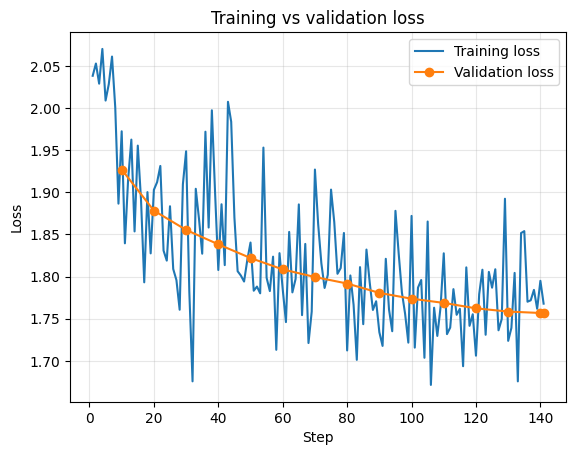

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

hist  = trainer.state.log_history
train = pd.DataFrame([h for h in hist if "loss" in h])
val   = pd.DataFrame([h for h in hist if "eval_loss" in h])

plt.plot(train["step"], train["loss"], label="Training loss")
plt.plot(val["step"], val["eval_loss"], "o-", label="Validation loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This time the training loss and validation loss is not stable, but eventually they are gradually decrease.

# Inference

Base Model

In [ ]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(tokenizer, chat_template="gemma-4")

messages = [{
    "role": "user",
    "content": [{"type": "text", "text": "ហេតុអ្វីបានជាយន្តហោះអាចហោះបាន"}],
}]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(
    text=text,
    add_special_tokens=False,
    return_tensors="pt",
).to("cuda")

outputs = model.generate(
    **inputs,
    max_new_tokens=2048,
    temperature=0.5,
    top_p=0.95,
    top_k=64,
)

# decode only the newly generated tokens (skip the prompt)
new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
print(tokenizer.decode(new_tokens, skip_special_tokens=True))

យន្តហោះហោះបានដោយសារតែការលោត។ វាមិនមែនជាការលោតដែលអ្នកគិតនោះទេ។ វាជាការលោតដែលកើតឡើងដោយសារតែខ្យល់ដែលបក់ពីក្រោមស្លាបរបស់យន្តហោះ។ នេះត្រូវបានគេហៅថា lift។ តាមពិតទៅ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាចហោះបានដោយសារតែការលោត។ យន្តហោះអាច

Fine Tuned model

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type": "text", "text": "ហេតុអ្វីបានជាយន្តហោះអាចហោះបាន"}],
}]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(
    text=text,
    add_special_tokens=False,   # prompt already has <bos>
    return_tensors="pt",
).to("cuda")

# Turn LoRA adapters off → original base model
with model.disable_adapter():
    outputs = model.generate(
        **inputs,
        max_new_tokens=2048,
        temperature=0.5,
        top_p=0.95,
        top_k=64,
    )

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
print(tokenizer.decode(new_tokens, skip_special_tokens=True))

យន្តហោះអាចហោះបានដោយសារទៅលើកត្តាចំនួន ៤ យ៉ាងសំខាន់ដែលធ្វើការរួមគ្នា (ដែលគេច្រើនហៅថា **កម្លាំងទាំង ៤** ឬ **Four Forces of Flight**)។

ដើម្បីឱ្យយន្តហោះហោះបាន និងរក្សាលំនឹងក្នុងអាកាស យន្តត្រូវយក្សមតិលើកម្លាំងទាំង ៤ នេះ៖

### ១. កម្លាំងលើក (Lift)
នេះគឺជាកម្លាំងដែលធ្វើឱ្យយន្តហោះឡើងលើ។ វាបង្កើតឡើងដោយសារ **ស្លាបយន្តហោះ (Wings)**។
*   **គោលការណ៍បាស្គាល់ (Bernoulli's Principle):** ស្លាបយន្តហោះត្រូវបានរចនាឱ្យមានរាងកោងខាងលើ និងរាបស្មើខាងក្រោម។ នៅពេលយន្តហោះទៅមុខ ខ្យល់អាកាសដែលរត់កាត់ពីលើស្លាបត្រូវធ្វើដំណើរលឿរបឹllជាងខ្យល់ដែលរត់ពីក្រោម។ វានាំឱ្យសម្ពាធខ្យល់ពីលើទាបជាងពីក្រោម ដែលបង្កើតជាកម្លាំង "ទាញ" ឬ "រុច្រក" យន្តឱ្យឡើងលើ។
*   **ចលនាស៊ីតុបាន (Newton's Third Law):** នៅពេលស្លាបយន្តហោះរុញខ្យល់អាកាសទៅចុះក្រោម វានឹងរុច្រកយន្តឱ្យឡើងទៅលើវិញ។

### ២. កម្លាំងទាញ (Weight / Gravity)
នេះគឺជាកម្លាំងទាញដី ឬទម្ងន់របស់យន្តដែលទាញឱ្យវាធ្លាក់ចុះមកក្រោម។
*   ដើម្បីឱ្យយន្តហោះបាន **កម្លាំងលើក (Lift)** ត្រូវតែខ្លាំងជាង **កម្លængទាញ (Weight)**។
*   នៅពេលយន្តហោះចង់ហោះឡើង យន្តហោះត្រូវបង្កើតកម្លាំងលើកឱ្យខ្លាំងជាងទម្ងន់ខ្លួនវា។



save trained model locally

In [ ]:
model.save_pretrained("gemma-4")
tokenizer.save_pretrained("gemma-4")

Unsloth: Restored added_tokens_decoder metadata in gemma-4/tokenizer_config.json.


['gemma-4/processor_config.json']

load saved model

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "gemma-4",      # ← the folder you saved to, not tokenizer_config.json
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type": "text", "text": "តើទឹកពុះនៅសីតុណ្ហភាពប៉ុន្មាន?"}],
}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize = False,                # return a string
    add_generation_prompt = True,
)

from transformers import TextStreamer
inputs = tokenizer(
    text = [text],                   # ← keyword required for Gemma 4
    add_special_tokens = False,      # prompt already has <bos>
    return_tensors = "pt",
).to("cuda")

_ = model.generate(
    **inputs,
    max_new_tokens = 512,
    temperature = 0.5, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True, skip_special_tokens = True),
)

ទឹកពុះនៅសីតុណ្ហភាព 212°F (100°C) ។ នេះគឺនៅកម្ពស់សមុទ្រ។ នៅទីកន្លែងខ្ពស់ជាងនេះ សីតុណ្ហភាពដែលទឹកពុះគឺទាបជាង។
